# Experiment 4: Polynomial Regression and the Bias–Variance Trade-off
**Aim:** Fit polynomial regression with different degrees and observe how model complexity affects prediction accuracy (underfitting vs overfitting).

**Dataset:** Auto MPG (`auto_mpg.csv`): 398 cars. Feature = `horsepower`, Target = `mpg` (fuel efficiency).

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings("ignore")

Missing horsepower values: 6
Shape after dropping missing rows: (392, 9)


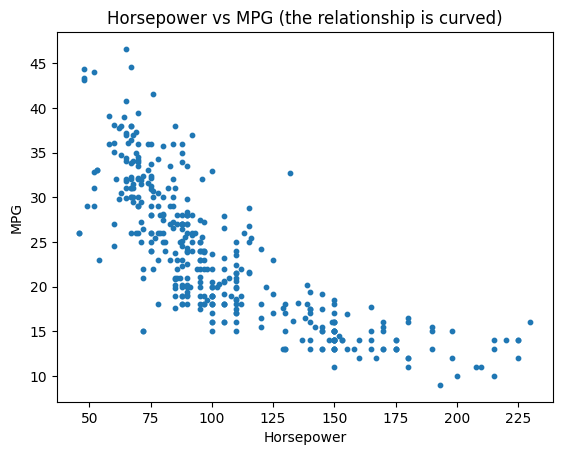

In [3]:
df = pd.read_csv("auto_mpg.csv")
print("Missing horsepower values:", df["horsepower"].isnull().sum())
df = df.dropna(subset=["horsepower"])
print("Shape after dropping missing rows:", df.shape)

X = df[["horsepower"]]
y = df["mpg"]

plt.scatter(X, y, s=10)
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Horsepower vs MPG (the relationship is curved)")
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Train one model per degree and record train / test error

In [5]:
degrees = [1, 2, 3, 5, 8, 10, 15, 20]
train_mse = []
test_mse = []

for d in degrees:
    model = make_pipeline(StandardScaler(), PolynomialFeatures(degree=d), LinearRegression())
    model.fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, model.predict(X_train)))
    test_mse.append(mean_squared_error(y_test, model.predict(X_test)))

results = pd.DataFrame({"Degree": degrees, "Train MSE": train_mse, "Test MSE": test_mse}).round(2)
results

,Degree,Train MSE,Test MSE
0,1,24.48,22.15
1,2,19.20,18.42
2,3,19.14,18.46
3,5,18.64,17.88
4,8,18.36,17.62
5,10,18.08,19.28
6,15,17.48,18.72
7,20,16.43,18.85


Best degree (lowest test MSE): 8


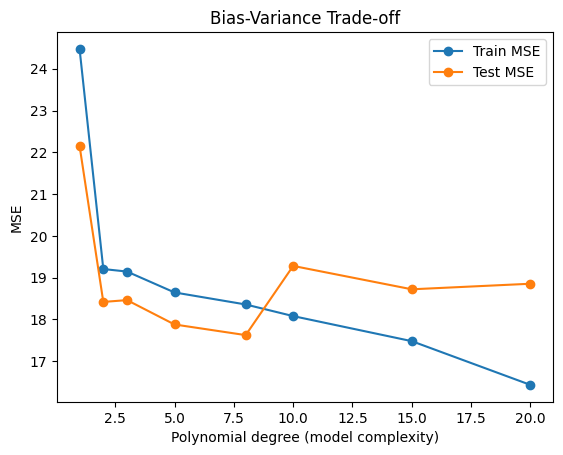

In [6]:
best_degree = results.loc[results["Test MSE"].idxmin(), "Degree"]
print("Best degree (lowest test MSE):", best_degree)

plt.plot(degrees, train_mse, marker="o", label="Train MSE")
plt.plot(degrees, test_mse, marker="o", label="Test MSE")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("MSE")
plt.title("Bias-Variance Trade-off")
plt.legend()
plt.show()

## Compare an underfit, a good and an overfit curve

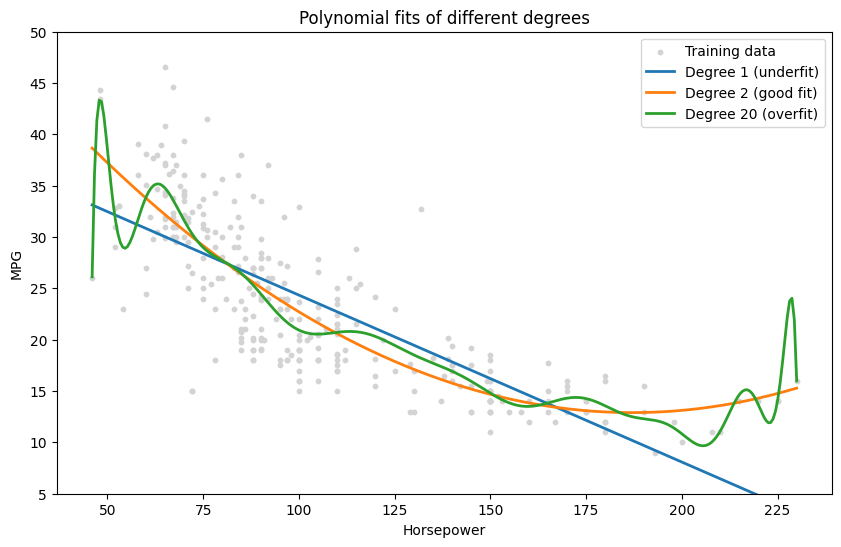

In [7]:
x_line = pd.DataFrame({"horsepower": np.linspace(X["horsepower"].min(), X["horsepower"].max(), 300)})

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, s=10, color="lightgray", label="Training data")
for d, label in [(1, "Degree 1 (underfit)"), (2, "Degree 2 (good fit)"), (20, "Degree 20 (overfit)")]:
    model = make_pipeline(StandardScaler(), PolynomialFeatures(degree=d), LinearRegression())
    model.fit(X_train, y_train)
    plt.plot(x_line, model.predict(x_line), linewidth=2, label=label)
plt.ylim(5, 50)
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Polynomial fits of different degrees")
plt.legend()
plt.show()

## Conclusion
- **Degree 1 (high bias / underfitting):** a straight line misses the curve, so train and test error are both high (~24 and ~22).
- **Degree 2–8 (balanced):** error drops sharply; this is the sweet spot.
- **Degree 10+ (high variance / overfitting):** train error keeps falling, but test error goes back up because the curve starts fitting noise.

So more complexity is not always better: choose the degree with the lowest **test** error.